In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load Dataset
df = pd.read_csv('data/reviews.csv')

In [3]:
# Exploring Dataset
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())
print(df['sentiment'].value_counts(dropna=False))
print(df.isnull().sum())

Shape: (10000, 5)
Columns: ['review_id', 'review_text', 'sentiment', 'category', 'source']
   review_id                                        review_text sentiment  \
0          1  This product exceeded my expectations in sever...  Positive   
1          2  The item is uncomfortable to use and poorly de...  Negative   
2          3  The product comes with a charging adapter and ...   Neutral   
3          4  Customer support was slow and did not solve my...  Negative   
4          5  The design is simple, attractive, and comforta...  Positive   

         category           source  
0           Books     Online Store  
1           Books     Online Store  
2          Travel  Customer Survey  
3  Home & Kitchen          Website  
4          Sports     Online Store  
sentiment
Positive    3334
Negative    3333
Neutral     3333
Name: count, dtype: int64
review_id      0
review_text    0
sentiment      0
category       0
source         0
dtype: int64


In [4]:
# Getting some info and stastical summary about data
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10000 non-null  int64
 1   review_text  10000 non-null  str  
 2   sentiment    10000 non-null  str  
 3   category     10000 non-null  str  
 4   source       10000 non-null  str  
dtypes: int64(1), str(4)
memory usage: 1.5 MB
None
         review_id
count  10000.00000
mean    5000.50000
std     2886.89568
min        1.00000
25%     2500.75000
50%     5000.50000
75%     7500.25000
max    10000.00000


In [5]:
# counting number of unique and duplicated entries
print("Unique review texts:", df['review_text'].nunique())
print("Duplicates in review_text:", df['review_text'].duplicated().sum())
print("Categories:", df['category'].value_counts())
print("Sources:", df['source'].value_counts())

Unique review texts: 300
Duplicates in review_text: 9700
Categories: category
Travel            1305
Clothing          1288
Sports            1278
Beauty            1272
Home & Kitchen    1245
Electronics       1239
Food & Grocery    1205
Books             1168
Name: count, dtype: int64
Sources: source
Online Store       2590
Customer Survey    2495
Website            2478
Mobile App         2437
Name: count, dtype: int64


In [6]:
# checking unique reviews on sentiments
print(df.groupby('sentiment')['review_text'].nunique())

sentiment
Negative    100
Neutral     100
Positive    100
Name: review_text, dtype: int64


In [7]:
df

,review_id,review_text,sentiment,category,source
0,1,This product exceeded my expectations in sever...,Positive,Books,Online Store
1,2,The item is uncomfortable to use and poorly de...,Negative,Books,Online Store
2,3,The product comes with a charging adapter and ...,Neutral,Travel,Customer Survey
3,4,Customer support was slow and did not solve my...,Negative,Home & Kitchen,Website
4,5,"The design is simple, attractive, and comforta...",Positive,Sports,Online Store
...,...,...,...,...,...
9995,9996,The battery drains quickly and does not last a...,Negative,Electronics,Customer Survey
9996,9997,I have been using the product for about one we...,Neutral,Books,Mobile App
9997,9998,The box included the accessories listed in the...,Neutral,Books,Website
9998,9999,"I really like this product; it is useful, reli...",Positive,Electronics,Online Store


Saved summary plot successfully.


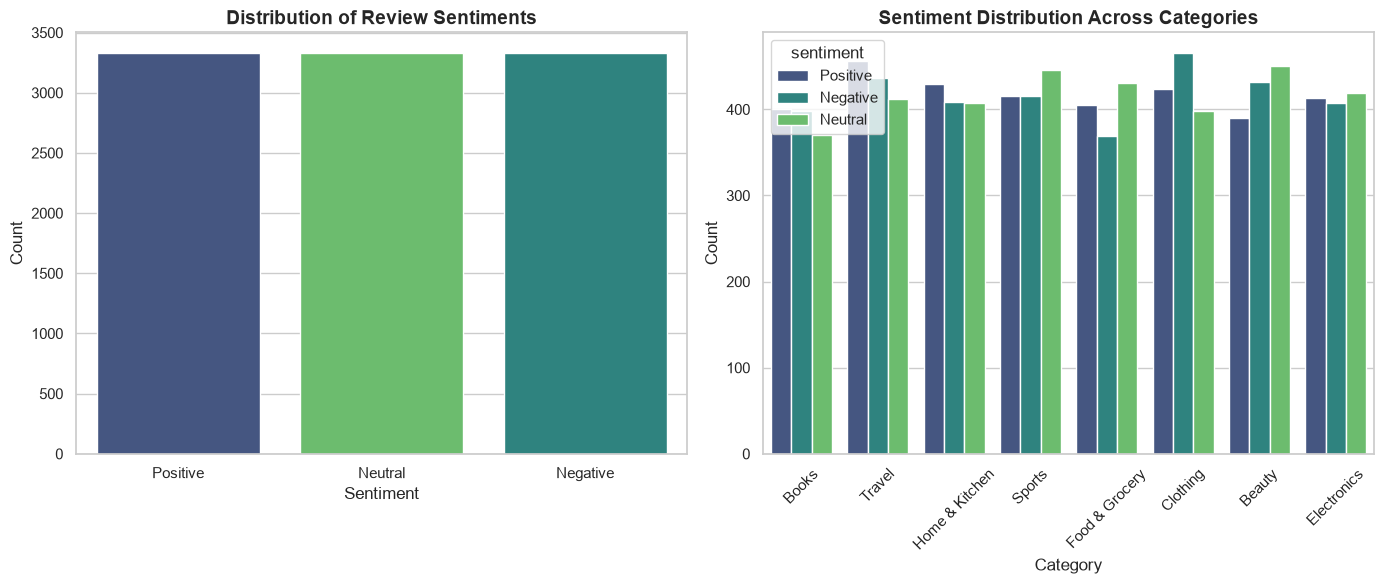

In [8]:
# Set style
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Sentiment Distribution
sns.countplot(data=df, x='sentiment', order=['Positive', 'Neutral', 'Negative'], palette='viridis', hue = 'sentiment', ax=axes[0])
axes[0].set_title('Distribution of Review Sentiments', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sentiment', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)

# Plot 2: Sentiment Distribution by Category
sns.countplot(data=df, x='category', hue='sentiment', palette='viridis', ax=axes[1])
axes[1].set_title('Sentiment Distribution Across Categories', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Category', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('reviews_visualization_summary.png', dpi=300)
print("Saved summary plot successfully.")

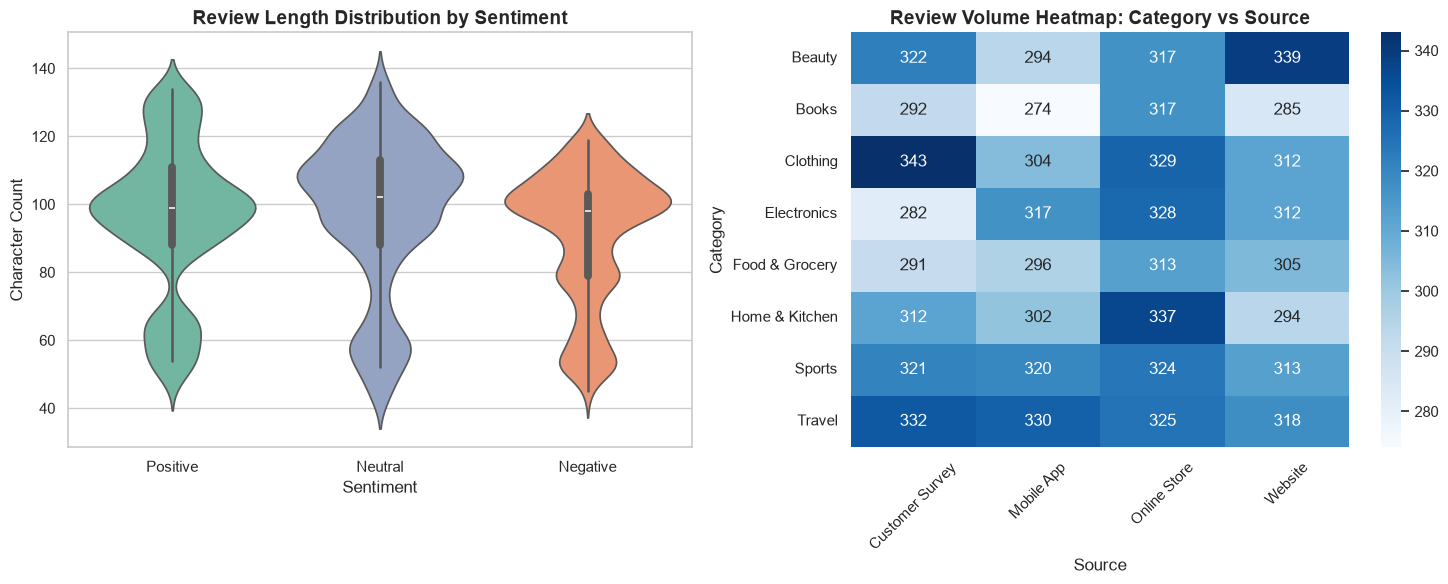

In [9]:
# Set theme
sns.set_theme(style="whitegrid")

# Create figure with 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Plot 1: Review Length Distribution by Sentiment ---
df['review_length'] = df['review_text'].apply(len)
sns.violinplot(
    data=df, 
    x='sentiment', 
    y='review_length', 
    order=['Positive', 'Neutral', 'Negative'], 
    palette='Set2',
    hue='sentiment',
    ax=axes[0]
)
axes[0].set_title('Review Length Distribution by Sentiment', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sentiment', fontsize=12)
axes[0].set_ylabel('Character Count', fontsize=12)

# --- Plot 2: Heatmap of Category vs Source ---
cross_tab = pd.crosstab(df['category'], df['source'])
sns.heatmap(
    cross_tab, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    ax=axes[1]
)
axes[1].set_title('Review Volume Heatmap: Category vs Source', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Source', fontsize=12)
axes[1].set_ylabel('Category', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('additional_reviews_visualizations.png', dpi=300)
plt.show()

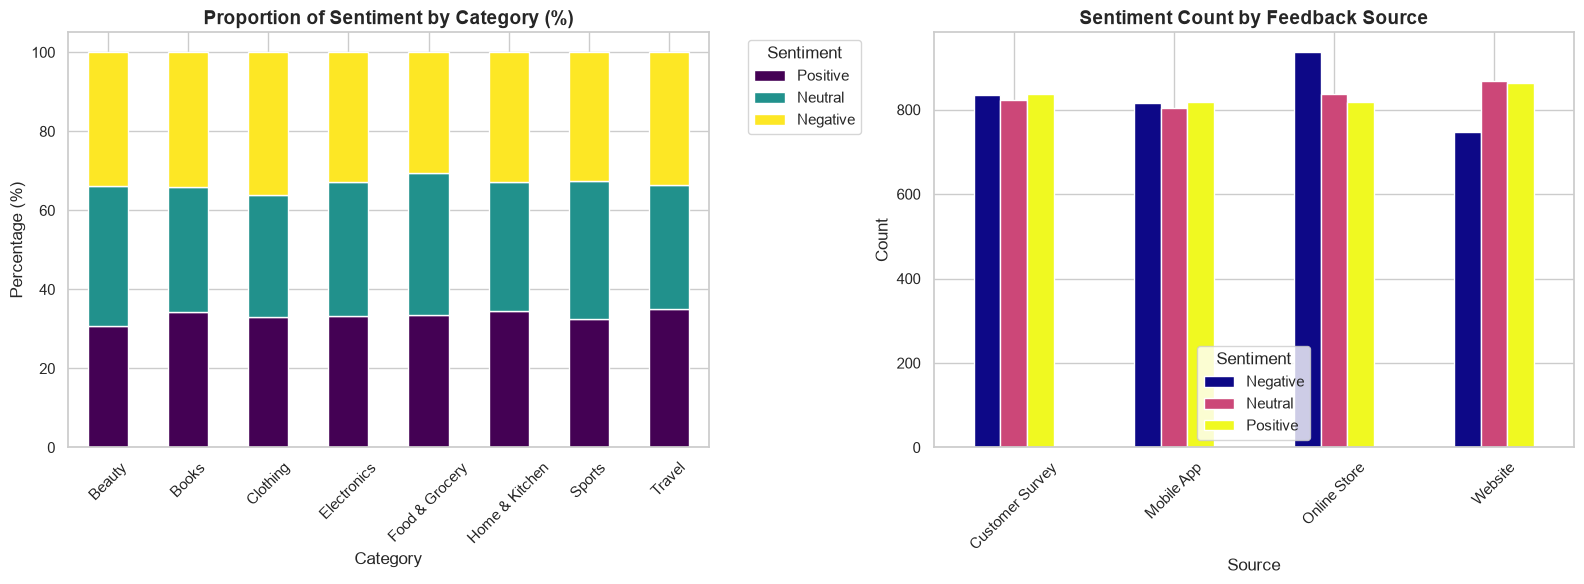

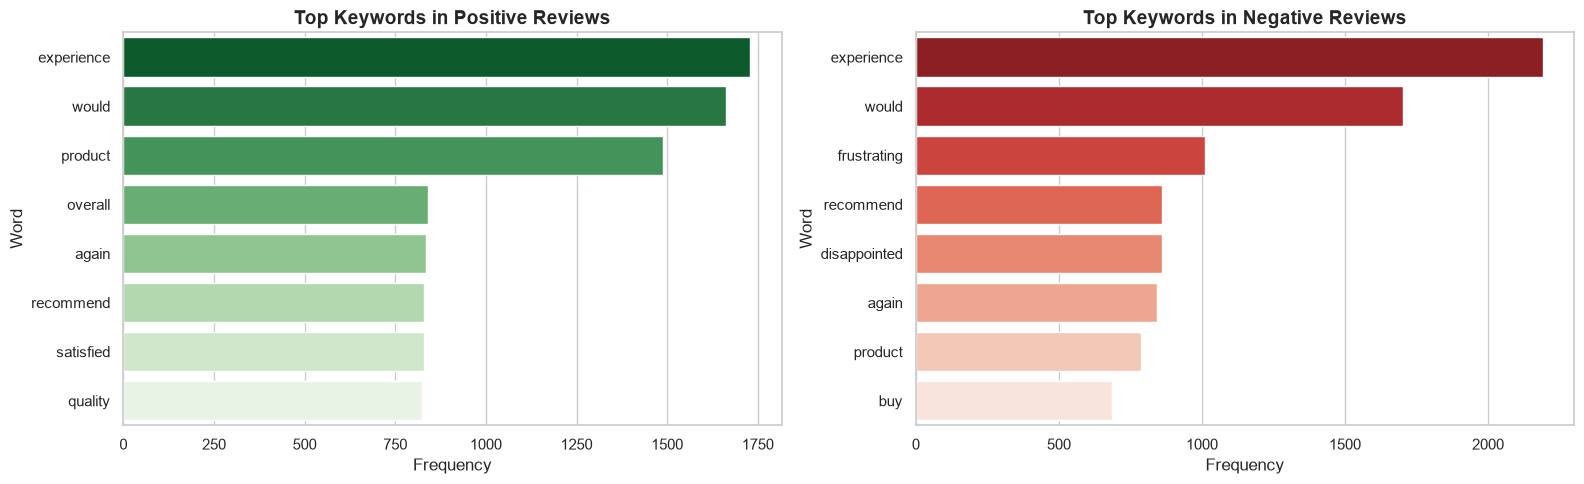

In [10]:
from collections import Counter
import re

# --- Figure 1: Proportional Category Breakdown & Source Counts ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cat_sent = pd.crosstab(df['category'], df['sentiment'], normalize='index') * 100
cat_sent[['Positive', 'Neutral', 'Negative']].plot(kind='bar', stacked=True, colormap='viridis', ax=axes[0])
axes[0].set_title('Proportion of Sentiment by Category (%)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Category', fontsize=12)
axes[0].set_ylabel('Percentage (%)', fontsize=12)
axes[0].legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[0].tick_params(axis='x', rotation=45)

source_sent = pd.crosstab(df['source'], df['sentiment'])
source_sent.plot(kind='bar', ax=axes[1], colormap='plasma')
axes[1].set_title('Sentiment Count by Feedback Source', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Source', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].legend(title='Sentiment')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('additional_visualizations_2.png', dpi=300)
plt.show()

# --- Figure 2: Keyword Frequency Analysis ---
stop_words = {'the', 'a', 'an', 'and', 'is', 'it', 'to', 'in', 'of', 'for', 'on', 'with', 'this', 'was', 'i', 'my', 'be', 'at', 'as', 'so', 'that', 'have', 'are', 'not', 'but', 'by', 'from'}

def get_top_words(sentiment_type, n=8):
    text_data = " ".join(df[df['sentiment'] == sentiment_type]['review_text'].astype(str))
    words = re.findall(r'\b[a-zA-Z]{3,}\b', text_data.lower())
    filtered = [w for w in words if w not in stop_words]
    return Counter(filtered).most_common(n)

pos_words = pd.DataFrame(get_top_words('Positive', 8), columns=['Word', 'Count'])
neg_words = pd.DataFrame(get_top_words('Negative', 8), columns=['Word', 'Count'])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=pos_words, x='Count', y='Word', palette='Greens_r', hue='Word', ax=axes[0])
axes[0].set_title('Top Keywords in Positive Reviews', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Frequency', fontsize=12)

sns.barplot(data=neg_words, x='Count', y='Word', palette='Reds_r',hue='Word', ax=axes[1])
axes[1].set_title('Top Keywords in Negative Reviews', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Frequency', fontsize=12)

plt.tight_layout()
plt.savefig('keyword_frequency_visualizations.png', dpi=300)
plt.show()

In [11]:
# Model Training
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

X = df['review_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    "Logistic Regression": Pipeline([('tfidf', TfidfVectorizer(stop_words='english')), ('clf', LogisticRegression(max_iter=1000))]),
    "Linear SVM": Pipeline([('tfidf', TfidfVectorizer(stop_words='english')), ('clf', LinearSVC(random_state=42))]),
    "Naive Bayes": Pipeline([('tfidf', TfidfVectorizer(stop_words='english')), ('clf', MultinomialNB())]),
    "Random Forest": Pipeline([('tfidf', TfidfVectorizer(stop_words='english')), ('clf', RandomForestClassifier(n_estimators=100, random_state=42))])
}

# Model Evaluation
review_labels = ['Positive', 'Neutral', 'Negative']
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    conf = confusion_matrix(y_test,y_pred, labels=review_labels)
    conf_df = pd.DataFrame(
    conf,
    index=[f'True: {l}' for l in review_labels],
    columns=[f'Pred: {l}' for l in review_labels],
    )
    results[name] = acc
    print(f"--- {name} ---")
    print(f"Accuracy: {acc:.4f}")
    print(f"Confusion_Matrix: \n {conf_df}")
    print(classification_report(y_test, y_pred))

--- Logistic Regression ---
Accuracy: 1.0000
Confusion_Matrix: 
                 Pred: Positive  Pred: Neutral  Pred: Negative
True: Positive             667              0               0
True: Neutral                0            666               0
True: Negative               0              0             667
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       667
     Neutral       1.00      1.00      1.00       666
    Positive       1.00      1.00      1.00       667

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

--- Linear SVM ---
Accuracy: 1.0000
Confusion_Matrix: 
                 Pred: Positive  Pred: Neutral  Pred: Negative
True: Positive             667              0               0
True: Neutral                0            666               0
True: Negative               0              0             667
  

In [12]:
# Hyperparameter-Tuning and Cross_Validation
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 1. Load the dataset
df = pd.read_csv('data/reviews.csv')
X = df['review_text']
y = df['sentiment']

# 2. Build a machine learning pipeline (Text Feature Extraction + Classifier)
pipeline = Pipeline(
    [
        ('tfidf', TfidfVectorizer(stop_words='english')),
        ('clf', LogisticRegression(max_iter=1000)),
    ]
)

# 3. Define the parameter grid for Grid Search ($C \in [0.1, 1.0, 10.0]$)
param_grid = {'clf__C': [0.1, 1.0, 10.0]}

# 4. Set up 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 5. Configure Grid Search
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,  # Uses all available CPU cores
)

# 6. Fit the model to the data
print('Running Grid Search and Cross-Validation...')
grid_search.fit(X, y)

# 7. Output Results
print('\n--- Hyperparameter Tuning Results ---')
print(f'Best Parameters: {grid_search.best_params_}')
print(f'Mean Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%')

# Display performance across all tested C values
results = pd.DataFrame(grid_search.cv_results_)
for mean_score, params in zip(
    results['mean_test_score'], results['params']
):
  print(f"Parameters: {params} | Accuracy: {mean_score * 100:.2f}%")

Running Grid Search and Cross-Validation...

--- Hyperparameter Tuning Results ---
Best Parameters: {'clf__C': 0.1}
Mean Cross-Validation Accuracy: 100.00%
Parameters: {'clf__C': 0.1} | Accuracy: 100.00%
Parameters: {'clf__C': 1.0} | Accuracy: 100.00%
Parameters: {'clf__C': 10.0} | Accuracy: 100.00%


In [13]:
import os
import joblib

# Making Folders for storing files in sentiment analysis folder
os.makedirs('sentiment-analysis/data', exist_ok=True)
os.makedirs('sentiment-analysis/models', exist_ok=True)
os.makedirs('sentiment-analysis/notebooks', exist_ok=True)

# Train best model (Logistic Regression or LinearSVC) on full training data or train/test
best_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', ngram_range=(1, 2))),
    ('clf', LogisticRegression(C=1.0, max_iter=1000))
])

best_pipeline.fit(X_train, y_train)

# Save model
model_path = 'models/sentiment_pipeline.pkl'
joblib.dump(best_pipeline, model_path)
print("Model saved to", model_path)

# Test loading
loaded_model = joblib.load(model_path)
print("Test prediction:", loaded_model.predict(["This product was amazing and exceeded all expectations!"]))
print("Test probabilities:", loaded_model.predict_proba(["This product was amazing and exceeded all expectations!"]))

Model saved to models/sentiment_pipeline.pkl
Test prediction: ['Positive']
Test probabilities: [[0.06542603 0.09475995 0.83981402]]
